In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


def load_results(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return pd.DataFrame(rows)


RESULTS_PATH = "../../results/length_experiment_results.jsonl"
df = load_results(RESULTS_PATH)
ok = df[df["status"] == "ok"].copy()
print(df["status"].value_counts())
print(f"Decoding accuracy: {100 * ok['decode_match'].mean():.1f}%")

status
ok    105
Name: count, dtype: int64
Decoding accuracy: 100.0%


In [2]:
length_table = ok.groupby("n_bits")["rating"].agg(n="count", mean="mean", median="median", sd="std").reset_index()
length_table.insert(1, "n_chars", length_table["n_bits"] // 8)
length_table["ci95"] = stats.t.ppf(0.975, length_table["n"] - 1) * length_table["sd"] / np.sqrt(length_table["n"])
print(length_table.round(2).to_string(index=False))

fit = stats.linregress(ok["n_bits"], ok["rating"])
r2_means = stats.linregress(length_table["n_bits"], length_table["mean"]).rvalue ** 2
print(f"Slope: {fit.slope * 16:.2f} points per 2 characters (p = {fit.pvalue:.2g}), R^2 of means = {r2_means:.3f}")

 n_bits  n_chars  n  mean  median    sd  ci95
     16        2 15 75.80    85.0 21.13 11.70
     32        4 15 72.80    70.0 15.25  8.45
     48        6 15 66.53    65.0 20.93 11.59
     64        8 15 61.07    65.0 19.16 10.61
     80       10 15 59.33    65.0 21.56 11.94
     96       12 15 54.67    60.0 20.02 11.08
    112       14 15 52.00    48.0 19.85 10.99
Slope: -4.10 points per 2 characters (p = 3.3e-05), R^2 of means = 0.982


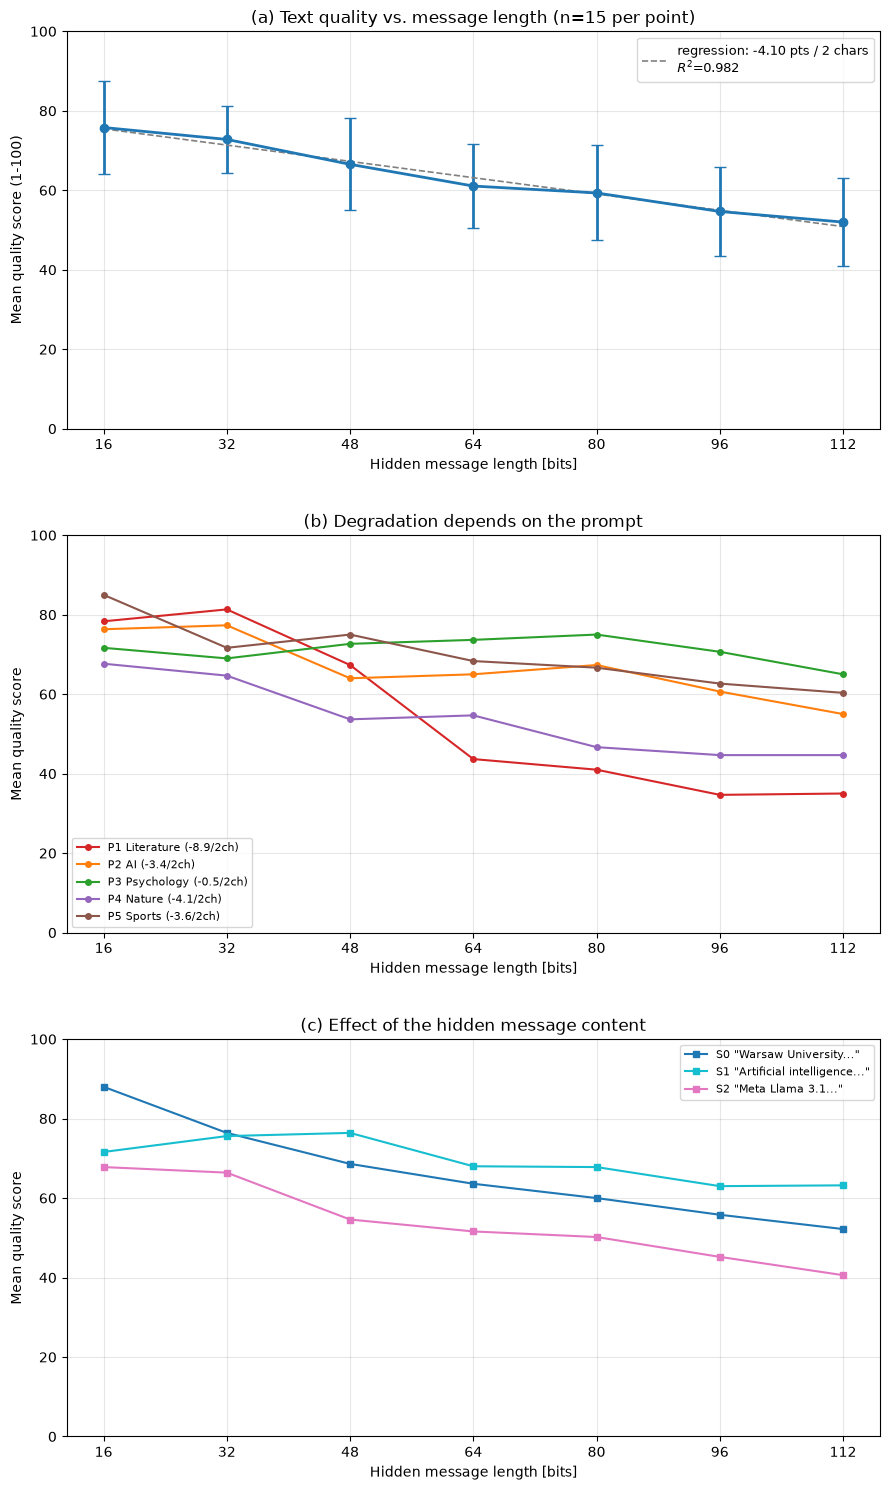

In [3]:
PROMPT_LABELS = ["P1 Literature", "P2 AI", "P3 Psychology", "P4 Nature", "P5 Sports"]
PROMPT_COLORS = ["tab:red", "tab:orange", "tab:green", "tab:purple", "tab:brown"]
SENT_LABELS = ['S0 "Warsaw University..."', 'S1 "Artificial intelligence..."', 'S2 "Meta Llama 3.1..."']
SENT_COLORS = ["tab:blue", "tab:cyan", "tab:pink"]


def slope_2ch(sub):
    return stats.linregress(sub["n_bits"], sub["rating"]).slope * 16


bits = length_table["n_bits"].values
n_per_point = int(length_table["n"].iloc[0])

fig, axes = plt.subplots(3, 1, figsize=(9, 15))

ax = axes[0]
ax.errorbar(length_table["n_bits"], length_table["mean"], yerr=length_table["ci95"],
            marker="o", capsize=4, lw=2, color="tab:blue")
xx = np.array([bits.min(), bits.max()])
ax.plot(xx, fit.intercept + fit.slope * xx, "--", color="gray", lw=1.2,
        label=f"regression: {fit.slope * 16:.2f} pts / 2 chars\n$R^2$={r2_means:.3f}")
ax.set_title(f"(a) Text quality vs. message length (n={n_per_point} per point)")
ax.set_ylabel("Mean quality score (1-100)")
ax.legend(loc="upper right", fontsize=9)

ax = axes[1]
for p in sorted(ok["prompt_idx"].unique()):
    sub = ok[ok["prompt_idx"] == p]
    m = sub.groupby("n_bits")["rating"].mean()
    ax.plot(m.index, m.values, marker="o", ms=4, color=PROMPT_COLORS[p],
            label=f"{PROMPT_LABELS[p]} ({slope_2ch(sub):.1f}/2ch)")
ax.set_title("(b) Degradation depends on the prompt")
ax.set_ylabel("Mean quality score")
ax.legend(loc="lower left", fontsize=8)

ax = axes[2]
for s in sorted(ok["sentence_idx"].unique()):
    m = ok[ok["sentence_idx"] == s].groupby("n_bits")["rating"].mean()
    ax.plot(m.index, m.values, marker="s", ms=4, color=SENT_COLORS[s], label=SENT_LABELS[s])
ax.set_title("(c) Effect of the hidden message content")
ax.set_ylabel("Mean quality score")
ax.legend(loc="upper right", fontsize=8)

for ax in axes:
    ax.set_xticks(bits)
    ax.set_xlabel("Hidden message length [bits]")
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)

plt.tight_layout(h_pad=3)
plt.show()